[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Ahmed-Bayoumy/MECH559/blob/HEAD/L10/L10_nelder_mead_failure_modes.ipynb)

# When Nelder-Mead Fails: Nonstationary Points, Saddles and "Maximizers"
### MECH 559 - Systems Optimization - L10
### Course Instructor: Dr. Ahmed Bayoumy
Author of the notebook: Dr. Ahmed Bayoumy

Companion notebook to the Nelder-Mead convergence slides. NM is a **heuristic**: it often
works very well, but it has no general convergence guarantee. This notebook reproduces the
failure modes discussed in class:

- **McKinnon (1998)**: on a smooth, strictly convex function NM converges to a point that is
  not even stationary;
- **saddle points**: a (nearly) flat simplex converges to a saddle and a standard stopping
  rule declares success there;
- **maximizers**: a frequent claim is that NM can converge to a maximizer. We test it and
  find exactly when it can (and when it cannot) happen.

## Learning objectives

By the end, students should be able to:

1. Reproduce McKinnon's counterexample and explain it: repeated inside contractions with a
   fixed best vertex, and a simplex that collapses orthogonally to the gradient.
2. Explain why a degenerate simplex makes NM blind to some directions, and why a saddle point
   can satisfy a diameter-based stopping rule.
3. Prove that NM cannot converge to a strict local maximizer of a continuous (smooth or not)
   function, and build the counterexamples that violate the assumptions.
4. Critically test claims about optimization algorithms by running them.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

try:
    import ipywidgets as widgets
    from IPython.display import display
    WIDGETS_AVAILABLE = True
except ImportError:
    WIDGETS_AVAILABLE = False

plt.rcParams.update({"font.size": 11, "figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
COLORS = {"simplex": "#D1495B", "fill": "#EDAE49", "best": "#1D5FA8", "optimum": "#D1495B",
          "limit": "#264653", "alt": "#2A9D5C"}
print(f"Optional widgets available: {WIDGETS_AVAILABLE}")


def nm_points(S):
    c = S[:-1].mean(axis=0)
    worst = S[-1]
    xr = c + (c - worst)
    return {"r": xr, "e": c + 2 * (c - worst), "oc": c + 0.5 * (xr - c), "ic": c + 0.5 * (worst - c),
            "shrink": S[0] + 0.5 * (S[1:] - S[0])}


def nelder_mead(func, simplex, max_iter=500, tol_diam=1e-8, max_eval=np.inf):
    """Standard NM (same rules as scipy.optimize.minimize(method='Nelder-Mead'))."""
    S = np.array(simplex, dtype=float)
    fv = np.array([func(v) for v in S])
    n_eval = len(S)
    history = [{"S": S.copy(), "f": fv.copy(), "op": "initial", "n_eval": n_eval}]
    for _ in range(max_iter):
        order = np.argsort(fv, kind="stable")
        S, fv = S[order], fv[order]
        if max(np.linalg.norm(a - b) for a in S for b in S) < tol_diam or n_eval >= max_eval:
            break
        p = nm_points(S)
        fr = func(p["r"]); n_eval += 1
        if fv[0] <= fr < fv[-2]:
            S[-1], fv[-1], op = p["r"], fr, "reflection"
        elif fr < fv[0]:
            fe = func(p["e"]); n_eval += 1
            S[-1], fv[-1], op = (p["e"], fe, "expansion") if fe < fr else (p["r"], fr, "reflection")
        else:
            outside = fr < fv[-1]
            xc = p["oc"] if outside else p["ic"]
            fc = func(xc); n_eval += 1
            if (outside and fc <= fr) or (not outside and fc < fv[-1]):
                S[-1], fv[-1] = xc, fc
                op = "outside contraction" if outside else "inside contraction"
            else:
                S[1:] = p["shrink"]
                fv[1:] = [func(v) for v in S[1:]]
                n_eval += len(S) - 1
                op = "shrink"
        history.append({"S": S.copy(), "f": fv.copy(), "op": op, "n_eval": n_eval})
    order = np.argsort(fv, kind="stable")
    return S[order][0], fv[order][0], history


def diameter(S):
    return max(np.linalg.norm(a - b) for a in S for b in S)

Optional widgets available: True


---
## 1. McKinnon's counterexample (1998)
#
$$
f(x, y) = \begin{cases} \theta\phi|x|^\tau + y + y^2 & x \le 0 \\ \theta x^\tau + y + y^2 & x > 0 \end{cases}
$$
#
With $(\tau, \theta, \phi) = (2, 6, 60)$, $f$ is strictly convex and $\mathcal{C}^1$, with
unique minimizer $x^\star = (0, -\tfrac12)$. McKinnon starts NM from the simplex
$\{(0,0), (1,1), (\lambda_1, \lambda_2)\}$ with $\lambda_{1,2} = (1 \pm \sqrt{33})/8$.
#
> **Predict:** $\nabla f(0,0) = (0, 1) \ne 0$, so $(0,0)$ is not stationary. Can NM still
> converge there?

In [2]:
def mckinnon(tau, theta, phi):
    def f(x):
        x1, y = x
        return (theta * phi * abs(x1) ** tau if x1 <= 0 else theta * x1 ** tau) + y + y ** 2
    return f


lam1, lam2 = (1 + np.sqrt(33)) / 8, (1 - np.sqrt(33)) / 8
S_mck = [(0.0, 0.0), (1.0, 1.0), (lam1, lam2)]
for params in [(2, 6, 60), (1, 15, 10), (3, 6, 400)]:
    xb, fb, H = nelder_mead(mckinnon(*params), S_mck, max_iter=60, tol_diam=0.0)
    ops = sorted({h["op"] for h in H[1:]})
    print(f"(tau, theta, phi) = {params}: operations = {ops}, best vertex = {np.round(xb, 10)}, "
          f"f = {fb:.3f}  (true minimum f(0,-1/2) = -0.25)")

(tau, theta, phi) = (2, 6, 60): operations = ['inside contraction'], best vertex = [0. 0.], f = 0.000  (true minimum f(0,-1/2) = -0.25)
(tau, theta, phi) = (1, 15, 10): operations = ['inside contraction'], best vertex = [0. 0.], f = 0.000  (true minimum f(0,-1/2) = -0.25)
(tau, theta, phi) = (3, 6, 400): operations = ['inside contraction'], best vertex = [0. 0.], f = 0.000  (true minimum f(0,-1/2) = -0.25)


For all three parameter sets (nonsmooth $\tau = 1$, $\mathcal{C}^1$ $\tau = 2$, $\mathcal{C}^2$ $\tau = 3$) NM performs **only inside contractions** and the best vertex never leaves $(0, 0)$. McKinnon shows the new vertex is always exactly $v^k = (\lambda_1^k, \lambda_2^k)$; let us check it and look at the shape of the simplex.

max |new vertex - (lambda1^k, lambda2^k)| over 30 iterations: 5.6e-17


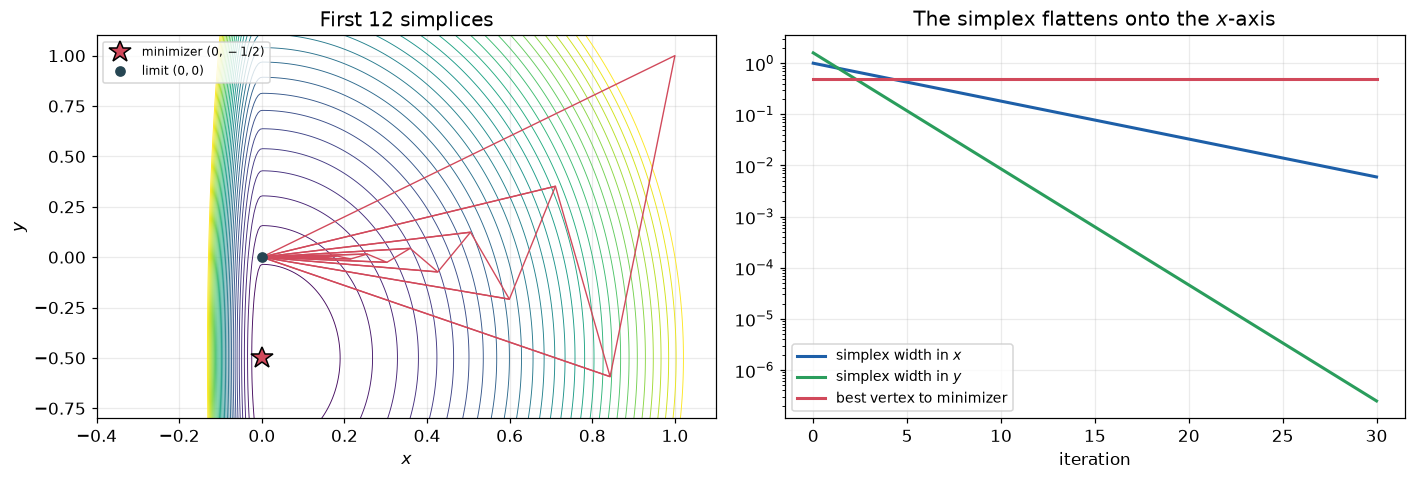

In [3]:
f_mck = mckinnon(2, 6, 60)
_, _, H = nelder_mead(f_mck, S_mck, max_iter=30, tol_diam=0.0)
max_dev = 0.0
for k, h in enumerate(H[1:], start=2):
    v_new = h["S"][[not np.allclose(v, 0) and not any(np.allclose(v, w) for w in H[k - 2]["S"]) for v in h["S"]]]
    if len(v_new):
        max_dev = max(max_dev, np.max(np.abs(v_new[0] - np.array([lam1 ** k, lam2 ** k]))))
print(f"max |new vertex - (lambda1^k, lambda2^k)| over 30 iterations: {max_dev:.1e}")

ks = np.arange(len(H))
width_x = [np.ptp(h["S"][:, 0]) for h in H]
width_y = [np.ptp(h["S"][:, 1]) for h in H]
dist = [np.linalg.norm(h["S"][np.argmin(h["f"])] - np.array([0, -0.5])) for h in H]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
xs = np.linspace(-0.4, 1.1, 300)
ys = np.linspace(-0.8, 1.1, 300)
XX, YY = np.meshgrid(xs, ys)
ZZ = np.where(XX <= 0, 360 * XX ** 2, 6 * XX ** 2) + YY + YY ** 2
axes[0].contour(XX, YY, ZZ, levels=np.linspace(-0.25, 6, 30), cmap="viridis", linewidths=0.6)
for h in H[:12]:
    P = np.vstack([h["S"], h["S"][0]])
    axes[0].plot(P[:, 0], P[:, 1], "-", color=COLORS["simplex"], lw=0.9)
axes[0].plot(0, -0.5, "*", color=COLORS["optimum"], ms=15, mec="k", label="minimizer $(0,-1/2)$")
axes[0].plot(0, 0, "o", color=COLORS["limit"], ms=6, label="limit $(0,0)$")
axes[0].set(xlabel="$x$", ylabel="$y$", title="First 12 simplices")
axes[0].legend(fontsize=8)
axes[1].semilogy(ks, width_x, color=COLORS["best"], lw=2, label="simplex width in $x$")
axes[1].semilogy(ks, width_y, color=COLORS["alt"], lw=2, label="simplex width in $y$")
axes[1].semilogy(ks, dist, color=COLORS["simplex"], lw=2, label="best vertex to minimizer")
axes[1].set(xlabel="iteration", title="The simplex flattens onto the $x$-axis")
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

Because $|\lambda_2| < \lambda_1 < 1$, the $y$-width vanishes much faster than the
$x$-width: the simplex collapses onto the $x$-axis, **orthogonal to the gradient**
$(0, 1)$, so it can never "see" the descent direction $(0, -1)$. The reflected point always
lands at $x < 0$, where $f$ is $\phi = 60$ times steeper, so it is always rejected.
McKinnon also shows this behaviour cannot occur for functions with more than three
continuous derivatives.
#
---
## 2. Converging to a saddle point
#
$$
f(x, y) = x^2 + \tfrac14 y^4 - \tfrac12 y^2
$$
#
has a saddle at $(0,0)$ ($f = 0$) and minimizers at $(0, \pm 1)$ ($f = -\tfrac14$). Start NM
from the nearly flat simplex $\{(2, \varepsilon), (1.5, -\varepsilon), (1, 0)\}$ and stop
when the diameter is below $10^{-6}$.

In [4]:
def f_saddle(x):
    return x[0] ** 2 + x[1] ** 4 / 4 - x[1] ** 2 / 2


print(f"{'eps':>8} | {'iterations':>10} | {'best point':>28} | {'f':>10}")
for eps in [0.0, 1e-8, 1e-4, 1e-2]:
    xb, fb, H = nelder_mead(f_saddle, [(2, eps), (1.5, -eps), (1, 0)], max_iter=500, tol_diam=1e-6)
    print(f"{eps:8.0e} | {len(H) - 1:10d} | {str(np.round(xb, 8)):>28} | {fb:10.2e}")

     eps | iterations |                   best point |          f
   0e+00 |         38 |              [2.e-07 0.e+00] |   4.10e-14
   1e-08 |         38 |            [ 2.e-07 -2.e-08] |   4.08e-14
   1e-04 |        125 | [-1.2000000e-07 -1.0000002e+00] |  -2.50e-01
   1e-02 |         72 | [ 1.0000000e-08 -9.9999964e-01] |  -2.50e-01


Every NM point is an **affine combination** of the current vertices, so a perfectly flat simplex ($\varepsilon = 0$) never leaves the $x$-axis, where $f(x, 0) = x^2$ is minimized at the saddle. With $\varepsilon = 10^{-8}$ NM reaches the saddle and the stopping rule ends the run. What if we let it continue?

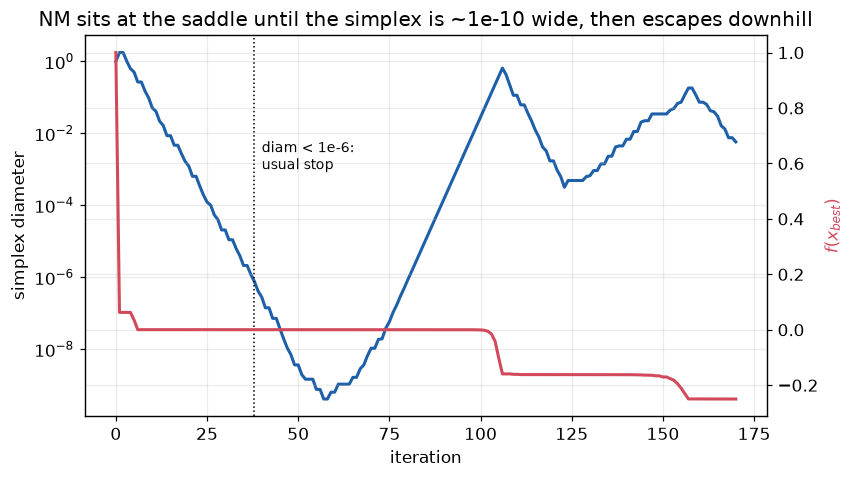

best point after 170 iterations: [-0.0017 -1.0004], f = -0.2500


In [5]:
_, _, H = nelder_mead(f_saddle, [(2, 1e-8), (1.5, -1e-8), (1, 0)], max_iter=170, tol_diam=0.0)
fbest = [h["f"].min() for h in H]
diam = [diameter(h["S"]) for h in H]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogy(diam, color=COLORS["best"], lw=2, label="simplex diameter")
ax2 = ax.twinx()
ax2.plot(fbest, color=COLORS["simplex"], lw=2, label="$f(x_{best})$")
ax.axvline(38, color="k", ls=":", lw=1)
ax.text(40, 1e-3, "diam < 1e-6:\nusual stop", fontsize=9)
ax.set(xlabel="iteration", ylabel="simplex diameter")
ax2.set_ylabel("$f(x_{best})$", color=COLORS["simplex"])
ax.set_title("NM sits at the saddle until the simplex is ~1e-10 wide, then escapes downhill")
plt.show()
print(f"best point after {len(H) - 1} iterations: {np.round(H[-1]['S'][np.argmin(H[-1]['f'])], 4)}, f = {fbest[-1]:.4f}")

During the escape $f(x_{best})$ only **decreases**: NM leaves the saddle along $-y$, the
direction in which the saddle is a maximizer - which is precisely a descent direction.
#
---
## 3. Can NM converge to a maximizer?
#
NM never replaces its best vertex by a worse one, so $f(x^k_{best})$ is nonincreasing.
Suppose the simplex collapsed onto a **strict local maximizer** $\bar x$. Then
$f(x^k_{best}) < f(\bar x)$ near $\bar x$, and since the sequence is nonincreasing it stays
below $f(x^K_{best}) < f(\bar x)$. If $f$ is continuous (smooth or not!) - in fact, lower
semicontinuous is enough - $x^k_{best} \to \bar x$ forces $f(x^k_{best}) \to f(\bar x)$:
a contradiction. So the only ways around it are to break the assumptions.
#
> **Predict:** for each case below, will NM end at the maximizer?

In [6]:
cases = {
    "spike: ||x||^2 with f(0) = 1 (discontinuous, strict max at 0)":
        (lambda x: 1.0 if (x[0] == 0 and x[1] == 0) else x[0] ** 2 + x[1] ** 2,
         [(0.7, 0.3), (0.4, 0.9), (1.1, 0.8)]),
    "ridge: y^4/4 - y^2/2, exactly flat simplex on y = 0 (non-strict max)":
        (lambda x: x[1] ** 4 / 4 - x[1] ** 2 / 2, [(2.0, 0.0), (1.5, 0.0), (1.0, 0.0)]),
    "ridge: same, simplex perturbed by 1e-3":
        (lambda x: x[1] ** 4 / 4 - x[1] ** 2 / 2, [(2.0, 1e-3), (1.5, -1e-3), (1.0, 0.0)]),
    "smooth peak: 10 exp(-||x||^2), simplex around the peak":
        (lambda x: 10 * np.exp(-(x[0] ** 2 + x[1] ** 2)), [(-0.5, -0.5), (0.5, -0.5), (0.0, 0.5)]),
}
for name, (func, S0) in cases.items():
    xb, fb, H = nelder_mead(func, S0, max_iter=400, tol_diam=1e-10, max_eval=800)
    print(f"{name}\n    -> best = {np.round(xb, 6)}, f = {fb:.3g}, iterations = {len(H) - 1}\n")

spike: ||x||^2 with f(0) = 1 (discontinuous, strict max at 0)
    -> best = [-0. -0.], f = 1e-21, iterations = 73

ridge: y^4/4 - y^2/2, exactly flat simplex on y = 0 (non-strict max)
    -> best = [2. 0.], f = 0, iterations = 34

ridge: same, simplex perturbed by 1e-3
    -> best = [188.187251   1.      ], f = -0.25, iterations = 86

smooth peak: 10 exp(-||x||^2), simplex around the peak
    -> best = [ -9.96875 -27.625  ], f = 0, iterations = 45



- **Spike** (not lower semicontinuous at $0$): NM converges to the origin, a *strict local
  maximizer* - it never evaluates exactly $(0,0)$ and only sees the bowl $\|x\|^2$.
- **Ridge, flat simplex**: all vertices have the same value, every contraction fails, and NM
  shrinks onto $(2, 0)$, a *non-strict* local maximizer. A $10^{-3}$ perturbation is enough
  to escape to the valley $y = 1$, where $f = -1/4$.
- **Smooth peak**: NM simply walks downhill, away from the peak.
#
Claims that NM "wraps around a peak and shrinks onto it" contradict the monotone
argument above. Here is such a claim tested directly: a sharp Gaussian peak on top of a
downward paraboloid, with the starting simplex placed around the peak.

In [7]:
def deceptive(z):
    return -0.05 * (z[0] ** 2 + z[1] ** 2) + 5.0 * np.exp(-(z[0] ** 2 + z[1] ** 2) / 0.5)


S_trap = [(-0.5, -0.5), (0.5, -0.5), (0.0, 0.5)]
print("vertex values:", [round(float(deceptive(v)), 3) for v in S_trap], " peak value:", float(deceptive((0, 0))))
xb, fb, H = nelder_mead(deceptive, S_trap, max_iter=400, max_eval=400)
print(f"first operations: {[h['op'] for h in H[1:6]]}")
print(f"after 400 evaluations: x = {xb}, f = {fb:.2e}")

vertex values: [1.814, 1.814, 3.02]  peak value: 5.0
first operations: ['expansion', 'expansion', 'expansion', 'expansion', 'expansion']
after 400 evaluations: x = [-8.32785873e+44 -2.42744941e+45], f = -3.29e+89


The very first reflection lands at $(0, -1.5)$, already below every vertex, so NM
**expands away** from the peak and keeps going: the function is unbounded below.
#
---
## 4. Explore: how flat must the simplex be?

In [8]:
def explore_saddle(log10_eps=-8.0, iterations=160):
    eps = 0.0 if log10_eps <= -16 else 10.0 ** log10_eps
    _, _, H = nelder_mead(f_saddle, [(2, eps), (1.5, -eps), (1, 0)], max_iter=iterations, tol_diam=0.0)
    path = np.array([h["S"][np.argmin(h["f"])] for h in H])
    k_stop = next((k for k, h in enumerate(H) if diameter(h["S"]) < 1e-6), None)
    xs_ = np.linspace(-2.2, 2.2, 300)
    ys_ = np.linspace(-1.6, 1.6, 300)
    Xs, Ys = np.meshgrid(xs_, ys_)
    fig, ax = plt.subplots(figsize=(6.5, 4.8))
    ax.contour(Xs, Ys, Xs ** 2 + Ys ** 4 / 4 - Ys ** 2 / 2, levels=np.linspace(-0.24, 4, 30),
               cmap="viridis", linewidths=0.6)
    ax.plot(path[:, 0], path[:, 1], "o-", ms=2, color=COLORS["simplex"])
    ax.plot([0, 0], [-1, 1], "*", color=COLORS["optimum"], ms=14, mec="k")
    ax.plot(0, 0, "X", color="k", ms=9)
    ax.set(xlabel="$x$", ylabel="$y$",
           title=f"eps = {eps:.0e}: f_best = {H[-1]['f'].min():.4f}; diam<1e-6 at k = {k_stop}")
    plt.show()


if WIDGETS_AVAILABLE:
    display(widgets.interactive(
        explore_saddle,
        log10_eps=widgets.FloatSlider(value=-8, min=-16, max=-1, step=1, description="log10(eps)"),
        iterations=widgets.IntSlider(value=160, min=20, max=300, step=20, description="iterations"),
    ))
else:
    for value in (-16.0, -8.0, -2.0):
        explore_saddle(value)

interactive(children=(FloatSlider(value=-8.0, description='log10(eps)', max=-1.0, min=-16.0, step=1.0), IntSliâ€¦

---
## Takeaways
#
1. **McKinnon**: on smooth, strictly convex functions in 2-D, NM can converge to a
   nonstationary point through endless inside contractions; the simplex degenerates
   orthogonally to the gradient. (In 1-D, Lagarias et al. prove convergence for strictly
   convex functions.)
2. **Saddles**: a degenerate simplex is blind to whole directions; NM can reach a saddle and
   a diameter-based stopping rule declares success there.
3. **Maximizers**: for continuous - smooth or nonsmooth - functions, NM cannot converge to a
   strict local maximizer, because the best value never increases. It can end at a
   maximizer only when $f$ jumps up at that point, or at non-strict maximizers with an
   exactly degenerate simplex.
4. Test claims by running them: the "trap around a peak" script walks away from the peak.
5. Modern NM variants (sufficient decrease, restarts when the simplex degenerates) and
   methods with convergence theory (GPS, MADS) fix these failures.